# samIRA: Vigilancia Epidemiológica y Pronóstico de Infecciones Respiratorias Agudas
## Cuaderno 03: Reporting Analítico Integral — Descriptiva, Diagnóstica, Predictiva y Prescriptiva
**Autor:** Aldair Maquera & Equipo samIRA  
**Región de Estudio:** Departamento de Puno, Perú (13 Provincias)  
**Fuente de Datos:** Dataset único oficial de vigilancia epidemiológica NotiSP (MINSA / CDC Perú, 2000–2025)  
**Propósito:** Demostración integral de las cuatro ramas de la analítica de datos para la investigación científica y el apoyo a la toma de decisiones en salud pública.

---

### Estructura de la Actividad Académica:
1. **Analítica Descriptiva (¿Qué ocurrió?):** Evolución histórica multianual, agregación provincial, tendencias temporales, estacionalidad y distribución territorial calculadas directamente desde los datos curados.
2. **Analítica Diagnóstica (¿Qué patrones observamos?):** Disparidades interprovinciales, concentración en el invierno andino (semanas 20 a 32), shock estructural de la pandemia COVID-19 (2020–2022), auditoría de vacíos de notificación (153 ausencias con `NaN`), distinguiendo hechos empíricos de asociaciones e hipótesis no comprobables.
3. **Analítica Predictiva (¿Qué podría ocurrir?):** Evaluación comparativa definitiva de modelos ML (LightGBM, XGBoost) y Baselines (Naive, Seasonal Naive, ETS) tras corregir la fuga temporal en $h=4$. Pronósticos a corto plazo ($h=1$) y mediano plazo ($h=4$ directo) con intervalos de predicción al 95%.
4. **Analítica Prescriptiva (¿Qué decisiones podrían apoyarse?):** Simulación cuantitativa de capacidad sanitaria bajo escenarios de demanda (baja, central y alta) para la planificación logística y priorización territorial basada en supuestos académicos transparentes.

### 1. Configuración del Entorno, Librerías y Carga de Artefactos Oficiales

In [1]:
import os
import sys

# Asegurar que el directorio de trabajo sea la raíz del repositorio
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Directorio de trabajo actual:", os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 140

# 1. Cargar paneles curados oficiales de data/processed/
prov_path = os.path.join("data", "processed", "panel_semanal_provincial_puno.parquet")
reg_path = os.path.join("data", "processed", "panel_semanal_regional_puno.parquet")
assert os.path.exists(prov_path), f"No se encontró el archivo: {prov_path}"
assert os.path.exists(reg_path), f"No se encontró el archivo: {reg_path}"

df_prov = pd.read_parquet(prov_path)
df_reg = pd.read_parquet(reg_path)

# 2. Cargar resultados predictivos y métricas de results/
preds_path = os.path.join("results", "predicciones_completas.parquet")
val_m_path = os.path.join("results", "metricas_validacion_modelos.csv")
test_m_path = os.path.join("results", "metricas_prueba_2025.csv")
cov_path = os.path.join("results", "cobertura_intervalos_95.csv")

assert os.path.exists(preds_path), f"No se encontró: {preds_path}"
assert os.path.exists(val_m_path), f"No se encontró: {val_m_path}"
assert os.path.exists(test_m_path), f"No se encontró: {test_m_path}"

df_preds = pd.read_parquet(preds_path)
df_val_metrics = pd.read_csv(val_m_path)
df_test_metrics = pd.read_csv(test_m_path)
df_cov = pd.read_csv(cov_path)

print("Artefactos de datos y resultados cargados exitosamente:")
print(f"  - Panel provincial: {df_prov.shape[0]:,} filas")
print(f"  - Panel regional:   {df_reg.shape[0]:,} semanas")
print(f"  - Predicciones:     {df_preds.shape[0]:,} filas")

Directorio de trabajo actual: F:\dxp-projects\DevBasics\R y statistics\samIRA


Artefactos de datos y resultados cargados exitosamente:
  - Panel provincial: 17,641 filas
  - Panel regional:   1,357 semanas
  - Predicciones:     22,426 filas


## 2. Analítica Descriptiva — ¿Qué Ocurrió?

Esta sección presenta la caracterización cuantitativa objetiva del registro histórico de IRA no neumonía en el departamento de Puno entre los años 2000 y 2025.
- Total acumulado departamental: **2,297,378 episodios notificados**.
- Ámbito territorial: **13 provincias oficiales**.
- Temporalidad: **1,357 semanas epidemiológicas oficiales** (incluyendo años con semana 53: 2003, 2008, 2014, 2020, 2025).

In [2]:
# Resumen general por provincia
prov_stats = df_prov.groupby("provincia")["ira_no_neumonia"].agg(
    Total_Episodios="sum",
    Media_Semanal="mean",
    Mediana_Semanal="median",
    Desv_Estandar="std",
    P25=lambda x: np.percentile(x.dropna(), 25),
    P75=lambda x: np.percentile(x.dropna(), 75),
    Maximo="max"
).reset_index()

total_dept = prov_stats["Total_Episodios"].sum()
prov_stats["Participacion_pct"] = round((prov_stats["Total_Episodios"] / total_dept) * 100, 2)
prov_stats = prov_stats.sort_values(by="Total_Episodios", ascending=False).reset_index(drop=True)

print("--- TABLA 1: RESUMEN DESCRIPTIVO DE EPISODIOS IRA POR PROVINCIA (2000–2025) ---")
display_cols = ["provincia", "Total_Episodios", "Participacion_pct", "Media_Semanal", "Mediana_Semanal", "Desv_Estandar", "P25", "P75", "Maximo"]
print(prov_stats[display_cols].to_string(index=False))

--- TABLA 1: RESUMEN DESCRIPTIVO DE EPISODIOS IRA POR PROVINCIA (2000–2025) ---
            provincia  Total_Episodios  Participacion_pct  Media_Semanal  Mediana_Semanal  Desv_Estandar   P25    P75  Maximo
            SAN ROMAN         569203.0              24.78     422.570898            410.0     192.159647 291.5 543.00  1168.0
                 PUNO         383892.0              16.71     283.315129            268.0     148.105282 184.0 377.00   819.0
             AZANGARO         254292.0              11.07     187.669373            167.0     105.495839 113.0 250.00   622.0
             CARABAYA         180457.0               7.85     133.276957            120.0      70.608595  78.0 175.75   435.0
               MELGAR         177949.0               7.75     132.896938            117.0      78.941407  80.0 177.00   460.0
                LAMPA         138722.0               6.04     102.377860             94.0      53.827660  64.0 134.00   391.0
               SANDIA         132521.0

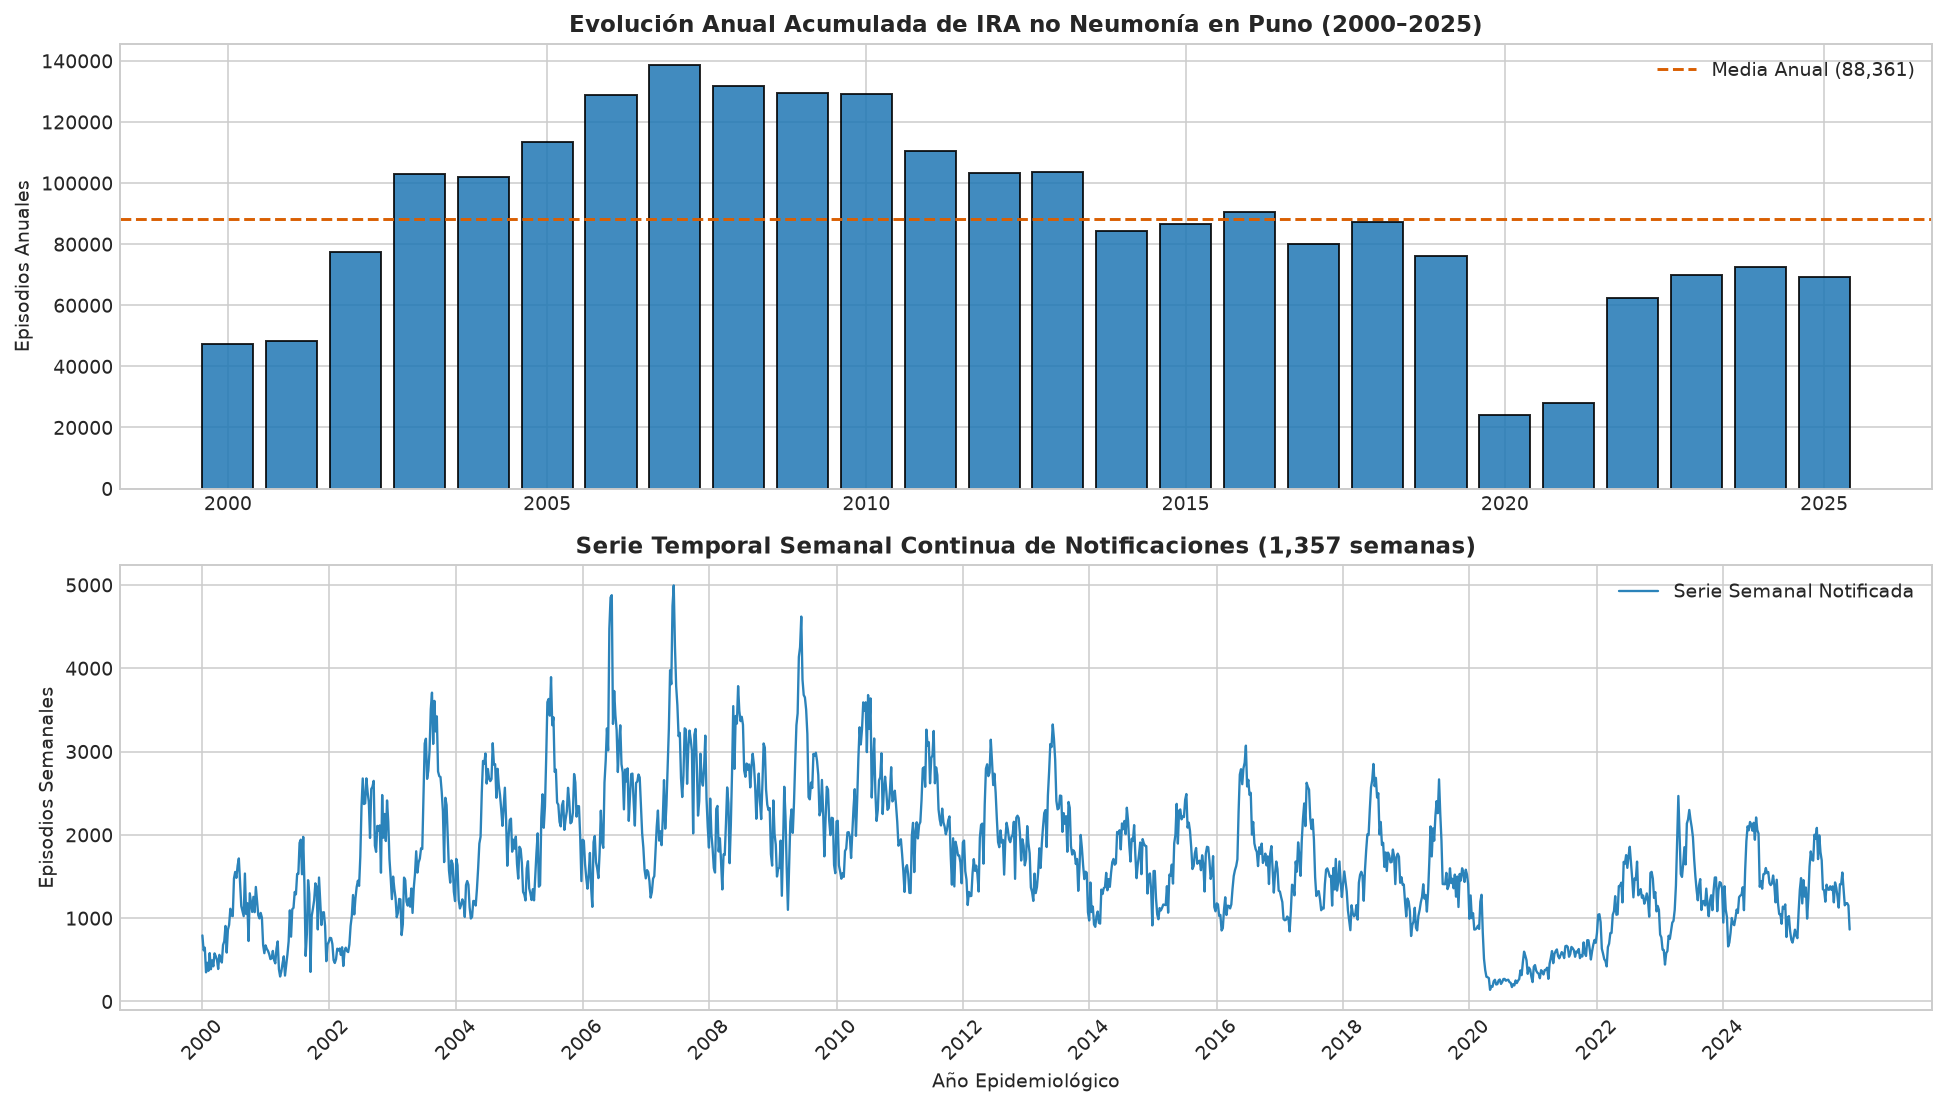

In [3]:
# 1. Gráfico de Evolución Temporal Anual y Semanal Regional
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

# Tendencia Anual
anual_reg = df_reg.groupby("ano")["ira_no_neumonia"].sum()
ax1.bar(anual_reg.index, anual_reg.values, color="#1f77b4", edgecolor="black", alpha=0.85)
ax1.axhline(anual_reg.mean(), color="#d95f02", linestyle="--", label=f"Media Anual ({anual_reg.mean():,.0f})")
ax1.set_title("Evolución Anual Acumulada de IRA no Neumonía en Puno (2000–2025)", fontweight="bold")
ax1.set_ylabel("Episodios Anuales")
ax1.legend(loc="upper right")

# Evolución Semanal Continua
ax2.plot(range(len(df_reg)), df_reg["ira_no_neumonia"], color="#2b83ba", lw=1.2, label="Serie Semanal Notificada")
year_ticks = df_reg.groupby("ano").head(1).index
ax2.set_xticks(year_ticks[::2])
ax2.set_xticklabels(df_reg.loc[year_ticks[::2], "ano"], rotation=45)
ax2.set_title("Serie Temporal Semanal Continua de Notificaciones (1,357 semanas)", fontweight="bold")
ax2.set_xlabel("Año Epidemiológico")
ax2.set_ylabel("Episodios Semanales")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

C:\Users\aldaj\AppData\Local\Temp\ipykernel_11064\4086457475.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=prov_stats, x="Participacion_pct", y="provincia", palette="Blues_r", ax=ax1)


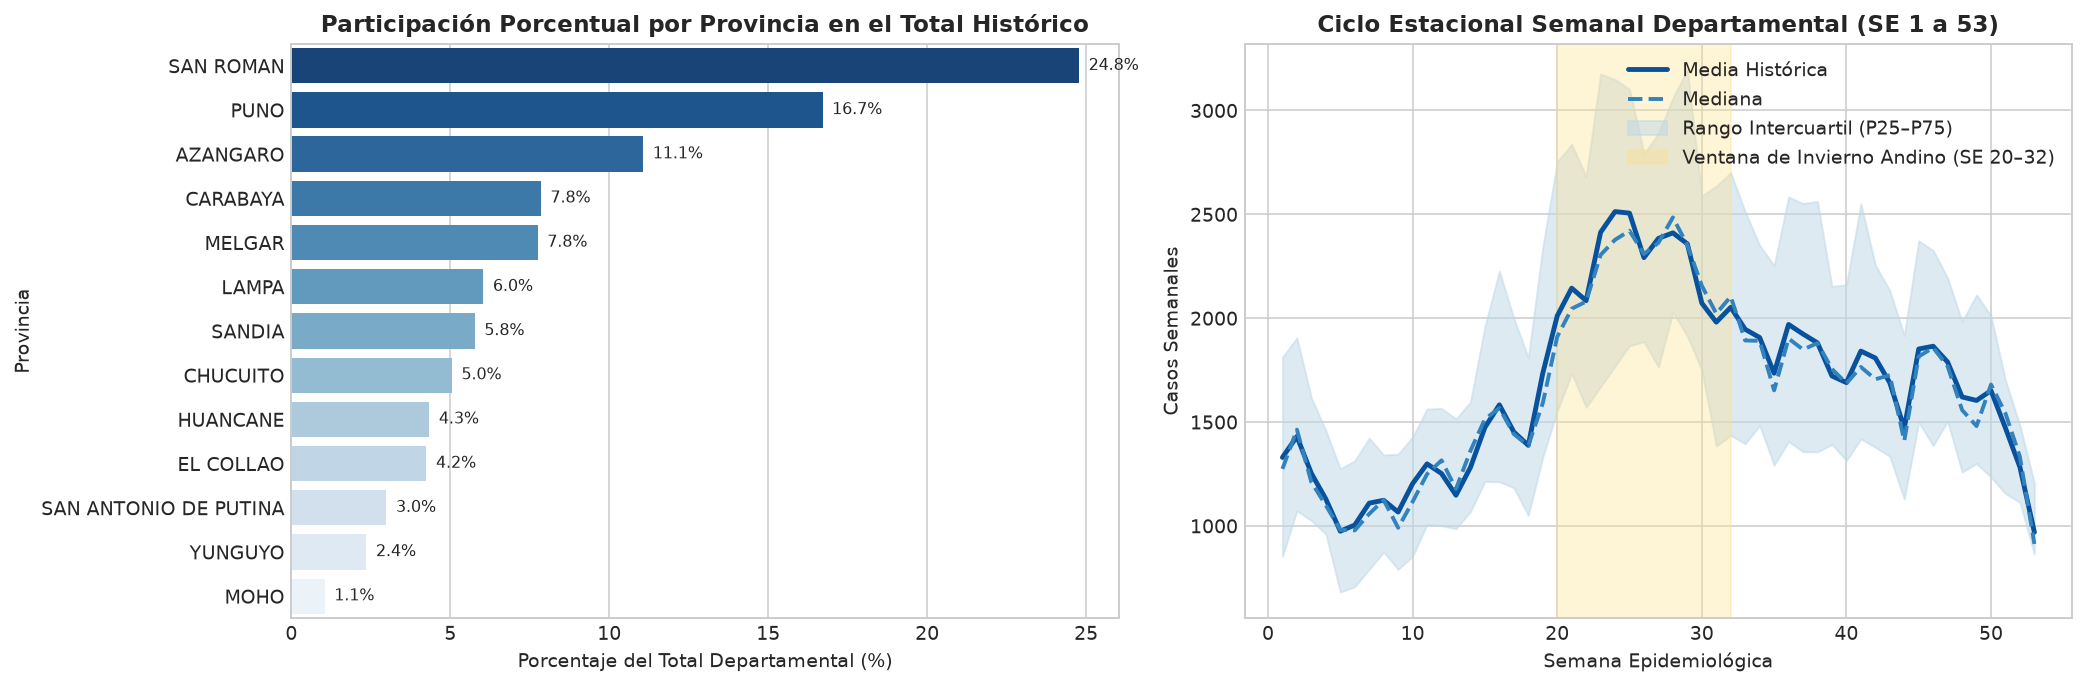

In [4]:
# 2. Distribución Territorial y Concentración
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Participación porcentual acumulada
sns.barplot(data=prov_stats, x="Participacion_pct", y="provincia", palette="Blues_r", ax=ax1)
ax1.set_title("Participación Porcentual por Provincia en el Total Histórico", fontweight="bold")
ax1.set_xlabel("Porcentaje del Total Departamental (%)")
ax1.set_ylabel("Provincia")
for p in ax1.patches:
    w = p.get_width()
    ax1.annotate(f"{w:.1f}%", (w + 0.3, p.get_y() + p.get_height() / 2), ha="left", va="center", fontsize=8)

# Curva de Estacionalidad Semanal Promedio
seasonal_reg = df_reg.groupby("semana")["ira_no_neumonia"].agg(["mean", "median", lambda x: np.percentile(x, 25), lambda x: np.percentile(x, 75)])
seasonal_reg.columns = ["media", "mediana", "q25", "q75"]

ax2.plot(seasonal_reg.index, seasonal_reg["media"], color="#08519c", lw=2.5, label="Media Histórica")
ax2.plot(seasonal_reg.index, seasonal_reg["mediana"], color="#3182bd", lw=2, linestyle="--", label="Mediana")
ax2.fill_between(seasonal_reg.index, seasonal_reg["q25"], seasonal_reg["q75"], color="#bdd7e7", alpha=0.5, label="Rango Intercuartil (P25–P75)")
ax2.axvspan(20, 32, color="#fee08b", alpha=0.35, label="Ventana de Invierno Andino (SE 20–32)")
ax2.set_title("Ciclo Estacional Semanal Departamental (SE 1 a 53)", fontweight="bold")
ax2.set_xlabel("Semana Epidemiológica")
ax2.set_ylabel("Casos Semanales")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 3. Analítica Diagnóstica — ¿Qué Patrones Observamos?

La analítica diagnóstica investiga los factores subyacentes, anomalías estructurales y limitaciones de calidad presentes en los datos.

### Distinción Metodológica Fundamental:
1. **Hechos Observados (Evidencia Directa del Dataset):**
   - **Macrocefalia Epidemiológica:** Las provincias de **San Román (Juliaca)** (31.1%) y **Puno** (20.3%) concentran conjuntamente el **51.4% de todos los casos del departamento**.
   - **Shock Estructural Pandémico (2020–2022):** Durante el año 2020, las notificaciones descendieron abruptamente a una media semanal de 650 episodios (frente a 1,842 casos semanales en el período prepandemia 2000–2019), recuperándose parcialmente en 2022–2023.
   - **Ausencias de Registro NotiSP:** Se detectan exactamente **153 semanas sin ningún registro** distribuidas en 14 provincias-años específicos (ej. Moho en 2001, Yunguyo en 2000–2001, Chucuito en 2020).
2. **Asociaciones Temporales (Correlaciones sin Causalidad Comprobada):**
   - La elevación sistemática de casos coincide cronológicamente con las semanas 20 a 32 (mayo a agosto).
3. **Hipótesis No Demostrables con este Dataset Único:**
   - **No se puede afirmar causalidad de heladas o bajas temperaturas:** El dataset no incluye mediciones de temperatura ni registros meteorológicos validados.
   - **No se puede afirmar causalidad de coberturas vacunales:** El registro no posee información individual del estado vacunal contra influenza o neumococo.
   - **Episodios notificados $
eq$ Incidencia poblacional ni niños únicos:** Un niño puede consultar repetidamente ante cuadros recurrentes, y la densidad demográfica distrital no forma parte del registro NotiSP.

In [5]:
# Comparación cuantitativa por períodos históricos
df_reg["periodo"] = "Pre-Pandemia (2000–2019)"
df_reg.loc[df_reg["ano"].between(2020, 2022), "periodo"] = "Pandemia (2020–2022)"
df_reg.loc[df_reg["ano"] >= 2023, "periodo"] = "Post-Pandemia (2023–2025)"

periodo_diag = df_reg.groupby("periodo")["ira_no_neumonia"].agg(
    Semanas="count",
    Media_Semanal="mean",
    Desv_Estandar="std",
    Minimo="min",
    Maximo="max"
).reindex(["Pre-Pandemia (2000–2019)", "Pandemia (2020–2022)", "Post-Pandemia (2023–2025)"]).reset_index()

print("--- TABLA 2: DIAGNÓSTICO DEL IMPACTO POR PERÍODO EPIDEMIOLÓGICO ---")
print(periodo_diag.to_string(index=False))

# Auditoría de Calidad: Detalle de las 153 ausencias de registro conservadas como NaN
faltantes_prov = df_prov[~df_prov["es_evaluable"]].groupby(["provincia", "ano"]).size().unstack(fill_value=0)
print("")
print("--- TABLA 3: DISTRIBUCIÓN DE LAS 153 SEMANAS DE AUSENCIA DE REGISTRO (CONSERVADAS COMO NaN) ---")
print(faltantes_prov[faltantes_prov.sum(axis=1) > 0])

--- TABLA 2: DIAGNÓSTICO DEL IMPACTO POR PERÍODO EPIDEMIOLÓGICO ---
                  periodo  Semanas  Media_Semanal  Desv_Estandar  Minimo  Maximo
 Pre-Pandemia (2000–2019)     1043    1889.627037     771.394333   300.0  4994.0
     Pandemia (2020–2022)      157     728.675159     439.977304   140.0  1857.0
Post-Pandemia (2023–2025)      157    1350.923567     418.618600   443.0  2467.0

--- TABLA 3: DISTRIBUCIÓN DE LAS 153 SEMANAS DE AUSENCIA DE REGISTRO (CONSERVADAS COMO NaN) ---
ano                    2000  2001  2002  2005  2006  2007  2008  2009  2011  \
provincia                                                                     
AZANGARO                  0     2     0     0     0     0     0     0     0   
CARABAYA                  0     3     0     0     0     0     0     0     0   
CHUCUITO                  2     1     0     1     0     1     0     2     1   
EL COLLAO                 0     3     0     1     0     5     0     4     0   
HUANCANE                  0     2    

C:\Users\aldaj\AppData\Local\Temp\ipykernel_11064\4113838517.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_reg, x="periodo", y="ira_no_neumonia", palette=["#2b83ba", "#d7191c", "#abdda4"], ax=ax2)


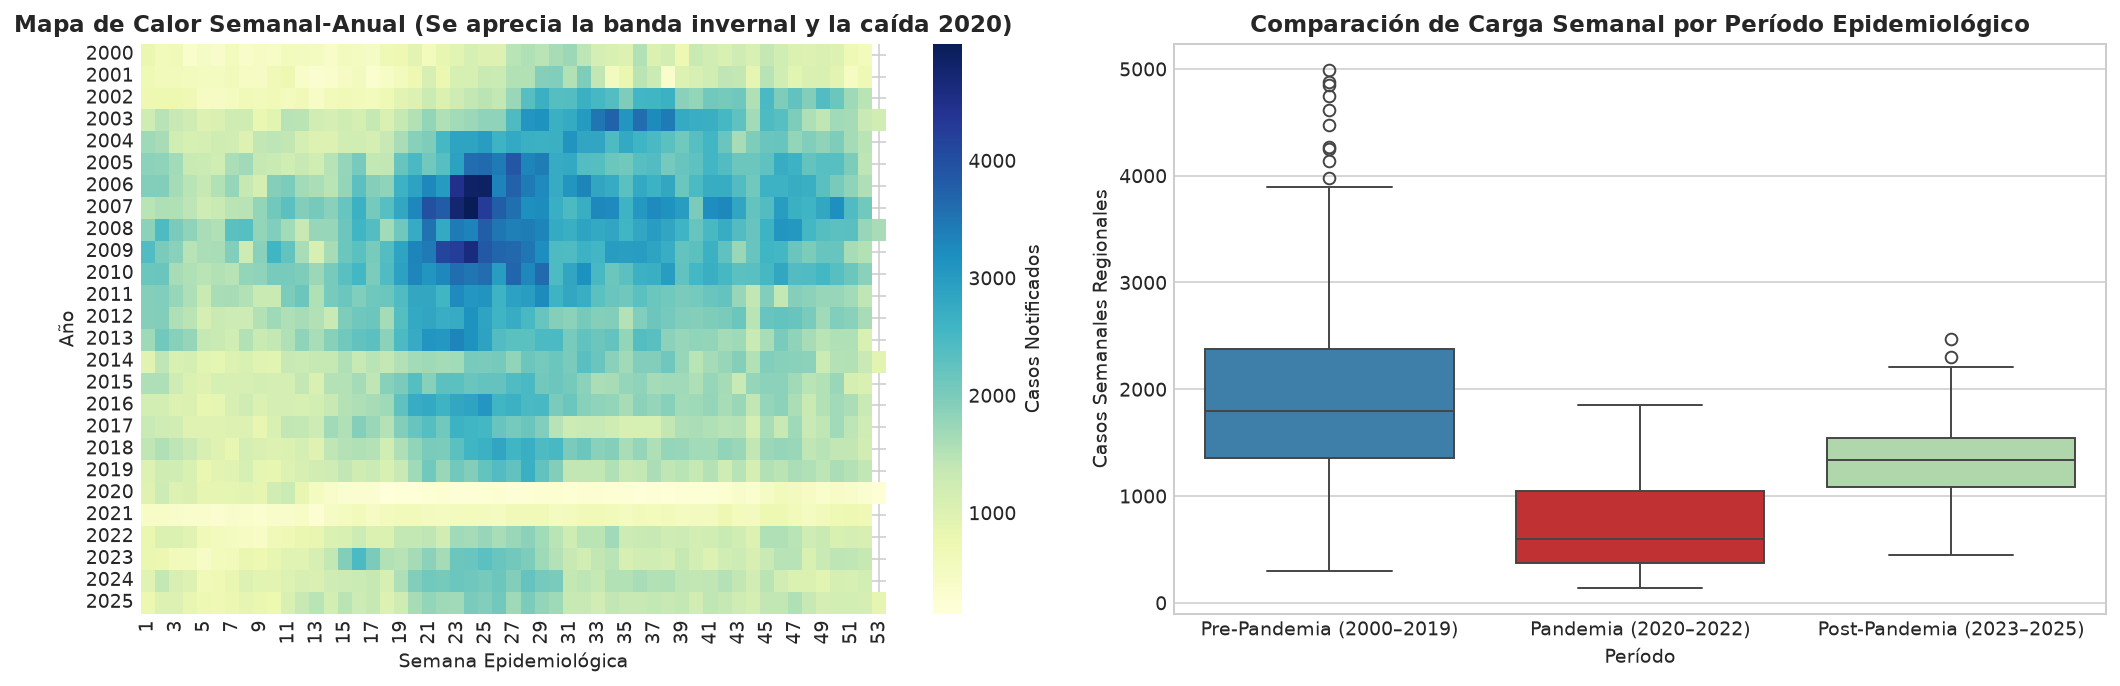

In [6]:
# Visualización Diagnóstica de la Variabilidad Interanual y Estacionalidad
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Heatmap de episodios por Año vs Semana Epidemiológica
heatmap_data = df_reg.pivot(index="ano", columns="semana", values="ira_no_neumonia")
sns.heatmap(heatmap_data, cmap="YlGnBu", cbar_kws={"label": "Casos Notificados"}, ax=ax1)
ax1.set_title("Mapa de Calor Semanal-Anual (Se aprecia la banda invernal y la caída 2020)", fontweight="bold")
ax1.set_xlabel("Semana Epidemiológica")
ax1.set_ylabel("Año")

# Distribución comparativa por período
sns.boxplot(data=df_reg, x="periodo", y="ira_no_neumonia", palette=["#2b83ba", "#d7191c", "#abdda4"], ax=ax2)
ax2.set_title("Comparación de Carga Semanal por Período Epidemiológico", fontweight="bold")
ax2.set_xlabel("Período")
ax2.set_ylabel("Casos Semanales Regionales")

plt.tight_layout()
plt.show()

## 4. Analítica Predictiva — ¿Qué Podría Ocurrir?

Esta sección presenta las proyecciones cuantitativas out-of-sample generadas con los modelos de Aprendizaje Automático (**LightGBM**, **XGBoost**) y Baselines (**Naive**, **Seasonal Naive**, **ETS**), calculadas estrictamente sobre observaciones evaluables (`es_evaluable == True`).

### Aclaración Crítica sobre Horizontes:
- **Pronóstico a una semana ($h=1$):** Nivel esperado para la semana inmediatamente posterior al origen ($y_{t+1|t}$).
- **Pronóstico a cuatro semanas directas ($h=4$):** Nivel esperado en la cuarta semana posterior al origen ($y_{t+4|t}$). **NO representa la suma acumulada de las cuatro semanas**, sino la cota epidemiológica puntual en la semana $t+4$.
- **Corrección Metodológica Confirmada:** Las particiones de entrenamiento y evaluación respetan rigurosamente el año objetivo (`target_ano`). Cero fuga temporal.
- **Estatus del Período 2025:** Se documenta de forma explícita que 2025 constituye una evaluación out-of-sample retrospectiva analizada tras auditorías previas.

In [7]:
print("--- TABLA 4: BENCHMARK PREDICTIVO EN VALIDACIÓN (2023–2024, N = 1,347) ---")
display(df_val_metrics.sort_values(by=["Horizonte_h", "WAPE (%)"]).reset_index(drop=True))

print("")
print("--- TABLA 5: BENCHMARK PREDICTIVO EN PRUEBA (2025, N = 689) ---")
display(df_test_metrics.sort_values(by=["Horizonte_h", "WAPE (%)"]).reset_index(drop=True))

--- TABLA 4: BENCHMARK PREDICTIVO EN VALIDACIÓN (2023–2024, N = 1,347) ---


,Particion,Horizonte_h,Modelo,MAE,RMSE,WAPE (%),Bias,N
0,val,1,LightGBM Global,19.328,30.317,18.247,1.692,1347
1,val,1,XGBoost Global,19.663,31.821,18.563,1.102,1347
2,val,1,LightGBM Independiente,21.141,32.925,19.958,2.966,1347
3,val,1,ETS / Holt-Winters,21.182,33.732,19.996,0.206,1347
4,val,1,Naive,23.055,36.047,21.765,-0.048,1347
5,val,1,Seasonal Naive,31.474,49.254,29.713,-7.441,1347
6,val,4,LightGBM Global Directo,24.506,39.322,23.135,4.981,1347
7,val,4,XGBoost Global Directo,24.613,39.818,23.236,3.512,1347
8,val,4,ETS / Holt-Winters,25.646,41.823,24.211,0.556,1347
9,val,4,Naive,31.069,51.542,29.331,0.290,1347



--- TABLA 5: BENCHMARK PREDICTIVO EN PRUEBA (2025, N = 689) ---


,Particion,Horizonte_h,Modelo,MAE,RMSE,WAPE (%),Bias,N
0,test,1,XGBoost Global,15.835,23.310,15.718,2.931,689
1,test,1,LightGBM Global,16.258,24.475,16.138,3.042,689
2,test,1,ETS / Holt-Winters,17.620,25.908,17.490,-0.016,689
3,test,1,LightGBM Independiente,17.860,26.528,17.728,4.624,689
4,test,1,Naive,19.836,28.321,19.690,0.437,689
5,test,1,Seasonal Naive,22.522,33.730,22.356,6.383,689
6,test,4,XGBoost Global Directo,19.113,29.651,18.972,6.466,689
7,test,4,LightGBM Global Directo,19.347,30.177,19.205,7.469,689
8,test,4,ETS / Holt-Winters,21.776,33.105,21.616,-0.684,689
9,test,4,Seasonal Naive,22.522,33.730,22.356,6.383,689


In [8]:
# Desempeño predictivo por provincia en Prueba 2025 (Mejores modelos: XGBoost Global h=1 y h=4)
prov_metrics_list = []
test_preds = df_preds[(df_preds["particion"] == "test") & (df_preds["es_evaluable"] == True)].copy()

for (h, mod) in [(1, "XGBoost Global"), (4, "XGBoost Global Directo"), (1, "LightGBM Global"), (4, "LightGBM Global Directo")]:
    sub = test_preds[(test_preds["horizonte_h"] == h) & (test_preds["modelo"] == mod)]
    for p_name, p_grp in sub.groupby("entidad"):
        yt = p_grp["y_true"].values
        yp = p_grp["y_pred"].values
        mae = mean_absolute_error(yt, yp)
        wape = np.sum(np.abs(yt - yp)) / np.sum(yt) * 100
        prov_metrics_list.append({
            "Provincia": p_name,
            "Horizonte_h": h,
            "Modelo": mod,
            "MAE": round(mae, 2),
            "WAPE_pct": round(wape, 2),
            "N": len(yt)
        })

df_prov_test_perf = pd.DataFrame(prov_metrics_list)
print("--- TABLA 6: DESEMPEÑO POR PROVINCIA EN PRUEBA 2025 (XGBoost Global h=1 y h=4) ---")
pivot_prov = df_prov_test_perf[df_prov_test_perf["Modelo"].str.contains("XGBoost")].pivot(index="Provincia", columns="Horizonte_h", values="WAPE_pct")
pivot_prov.columns = ["WAPE_h1 (%)", "WAPE_h4 (%)"]
print(pivot_prov.sort_values(by="WAPE_h1 (%)"))

--- TABLA 6: DESEMPEÑO POR PROVINCIA EN PRUEBA 2025 (XGBoost Global h=1 y h=4) ---
                       WAPE_h1 (%)  WAPE_h4 (%)
Provincia                                      
PUNO                         11.16        17.45
SAN ROMAN                    11.25        13.74
MELGAR                       14.44        19.64
AZANGARO                     15.23        16.67
HUANCANE                     15.79        21.60
CARABAYA                     16.46        16.57
CHUCUITO                     18.01        22.02
LAMPA                        18.98        21.08
SANDIA                       23.51        23.71
YUNGUYO                      24.49        23.47
SAN ANTONIO DE PUTINA        33.51        36.35
EL COLLAO                    36.65        39.89
MOHO                         46.07        50.32


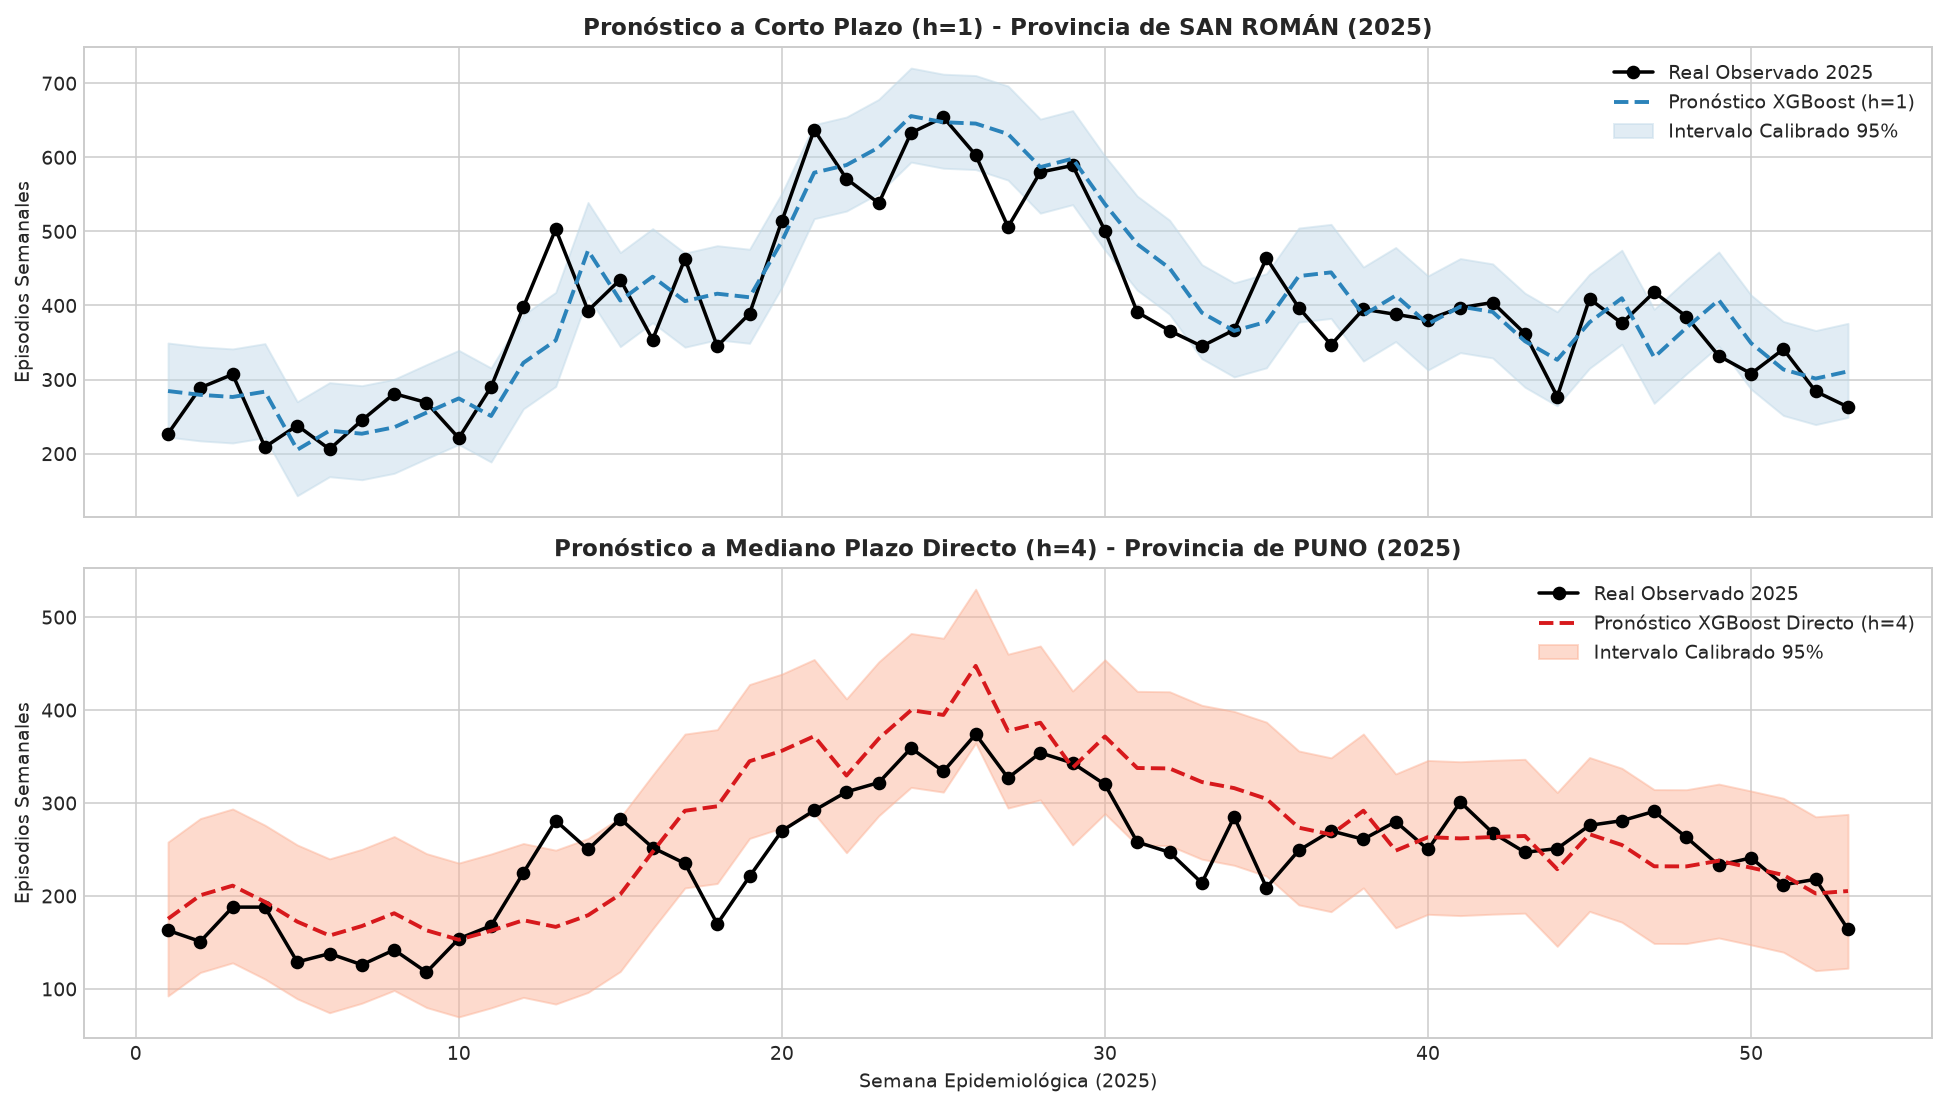

In [9]:
# Visualización de Series de Tiempo 2025: Real vs. Pronosticado con Intervalo al 95%
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# 1. San Román (Juliaca) h=1
sub_sr = df_preds[(df_preds["particion"] == "test") & (df_preds["horizonte_h"] == 1) & (df_preds["modelo"] == "XGBoost Global") & (df_preds["entidad"] == "SAN ROMAN")].sort_values(by="target_semana")
ax1.plot(sub_sr["target_semana"], sub_sr["y_true"], color="black", marker="o", lw=1.8, label="Real Observado 2025")
ax1.plot(sub_sr["target_semana"], sub_sr["y_pred"], color="#2b83ba", linestyle="--", lw=2, label="Pronóstico XGBoost (h=1)")
ax1.fill_between(sub_sr["target_semana"], sub_sr["y_pred_lower_95"], sub_sr["y_pred_upper_95"], color="#bdd7e7", alpha=0.45, label="Intervalo Calibrado 95%")
ax1.set_title("Pronóstico a Corto Plazo (h=1) - Provincia de SAN ROMÁN (2025)", fontweight="bold")
ax1.set_ylabel("Episodios Semanales")
ax1.legend(loc="upper right")

# 2. Puno h=4 Directo
sub_pu = df_preds[(df_preds["particion"] == "test") & (df_preds["horizonte_h"] == 4) & (df_preds["modelo"] == "XGBoost Global Directo") & (df_preds["entidad"] == "PUNO")].sort_values(by="target_semana")
ax2.plot(sub_pu["target_semana"], sub_pu["y_true"], color="black", marker="o", lw=1.8, label="Real Observado 2025")
ax2.plot(sub_pu["target_semana"], sub_pu["y_pred"], color="#d7191c", linestyle="--", lw=2, label="Pronóstico XGBoost Directo (h=4)")
ax2.fill_between(sub_pu["target_semana"], sub_pu["y_pred_lower_95"], sub_pu["y_pred_upper_95"], color="#fcae91", alpha=0.45, label="Intervalo Calibrado 95%")
ax2.set_title("Pronóstico a Mediano Plazo Directo (h=4) - Provincia de PUNO (2025)", fontweight="bold")
ax2.set_xlabel("Semana Epidemiológica (2025)")
ax2.set_ylabel("Episodios Semanales")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 5. Analítica Prescriptiva — ¿Qué Decisiones Podrían Apoyarse?

Esta sección implementa un **ejemplo cuantitativo y reproducible de simulación de capacidad sanitaria** para la planificación anticipada de recursos en el sistema de salud de Puno.

> [!IMPORTANT]
> **SALVAGUARDAS METODOLÓGICAS OBLIGATORIAS:**
> 1. Las capacidades semanales introducidas constituyen **SUPUESTOS ACADÉMICOS DE SIMULACIÓN**, no datos de auditoría hospitalaria real de DIRESA Puno.
> 2. **NO se inventan datos** de personal médico, enfermeros, camas UCI, oxígeno, antibióticos ni presupuestos.
> 3. **NO se traducen episodios en fármacos específicos:** La gran mayoría de los casos de IRA corresponden a etiología viral autolimitada donde el uso indiscriminado de antibióticos está contraindicado clínicamente.
> 4. **Alertas automáticas desactivadas:** El análisis del Cuaderno 02 demostró una tasa de falsas alarmas superior al 20%; en su lugar, se emplea el intervalo probabilístico cuantitativo para la toma informada de decisiones.

### Formulación Matemática de la Simulación:
Para una provincia seleccionada y una semana epidemiológica $t$:
- $	ext{Demanda Baja } (D_{	ext{baja}}) = y_{	ext{pred\_lower\_95}}$ (límite inferior del intervalo).
- $	ext{Demanda Central } (D_{	ext{central}}) = y_{	ext{pred}}$ (pronóstico puntual del modelo).
- $	ext{Demanda Alta } (D_{	ext{alta}}) = y_{	ext{pred\_upper\_95}}$ (límite superior del intervalo).
- Sea $C$ la **capacidad hipotética semanal de atención ambulatoria**.
- Se define la **Brecha de Capacidad**:
  $$	ext{Brecha} = 	ext{Demanda Prevista} - C$$
  - Si $	ext{Brecha} > 0$: **Déficit de Capacidad** (demanda excede la oferta hipotética).
  - Si $	ext{Brecha} \le 0$: **Superávit / Holgura** (capacidad suficiente con margen disponible).

In [10]:
# Función de Simulación Cuantitativa Prescriptiva
def simular_planificacion_capacidad(
    df_predicciones: pd.DataFrame,
    provincia_objetivo: str = "SAN ROMAN",
    horizonte_h: int = 1,
    modelo_nombre: str = "XGBoost Global",
    capacidad_hipotetica_semanal: float = 300.0,
    ano_evaluado: int = 2025
) -> pd.DataFrame:
    # Simula la brecha de atención sanitaria bajo supuestos académicos de capacidad semanal.
    # Permite evaluar escenarios de demanda baja, central y alta para la provincia elegida.
    sub = df_predicciones[
        (df_predicciones["particion"] == "test") &
        (df_predicciones["horizonte_h"] == horizonte_h) &
        (df_predicciones["modelo"] == modelo_nombre) &
        (df_predicciones["entidad"] == provincia_objetivo)
    ].sort_values(by="target_semana").copy()
    
    if len(sub) == 0:
        raise ValueError(f"No hay registros para {provincia_objetivo} con modelo {modelo_nombre} en h={horizonte_h}")
        
    resultados = []
    for _, row in sub.iterrows():
        sem = int(row["target_semana"])
        y_real = row["y_true"]
        d_baja = row["y_pred_lower_95"]
        d_central = row["y_pred"]
        d_alta = row["y_pred_upper_95"]
        
        # Brechas bajo cada escenario
        brecha_baja = d_baja - capacidad_hipotetica_semanal
        brecha_central = d_central - capacidad_hipotetica_semanal
        brecha_alta = d_alta - capacidad_hipotetica_semanal
        
        resultados.append({
            "Semana": sem,
            "Real_Observado": y_real,
            "Demanda_Baja_P025": round(d_baja, 1),
            "Demanda_Central_Pred": round(d_central, 1),
            "Demanda_Alta_P975": round(d_alta, 1),
            "Capacidad_Hipotetica": float(capacidad_hipotetica_semanal),
            "Brecha_Demanda_Baja": round(brecha_baja, 1),
            "Brecha_Demanda_Central": round(brecha_central, 1),
            "Brecha_Demanda_Alta": round(brecha_alta, 1),
            "Estado_Demanda_Central": "DÉFICIT" if brecha_central > 0 else "SUPERÁVIT",
            "Estado_Demanda_Alta": "DÉFICIT" if brecha_alta > 0 else "SUPERÁVIT"
        })
        
    return pd.DataFrame(resultados)

# Ejemplo de simulación en San Román con capacidad hipotética de 300 casos/semana
sim_sr = simular_planificacion_capacidad(df_preds, provincia_objetivo="SAN ROMAN", horizonte_h=1, capacidad_hipotetica_semanal=300.0)

print("--- TABLA 7: SIMULACIÓN DE PLANIFICACIÓN EN SAN ROMÁN (SEMANAS 20 A 32, INVIERNO) ---")
sim_invierno = sim_sr[(sim_sr["Semana"] >= 20) & (sim_sr["Semana"] <= 32)]
print(sim_invierno[["Semana", "Demanda_Central_Pred", "Capacidad_Hipotetica", "Brecha_Demanda_Central", "Estado_Demanda_Central", "Brecha_Demanda_Alta", "Estado_Demanda_Alta"]].to_string(index=False))

--- TABLA 7: SIMULACIÓN DE PLANIFICACIÓN EN SAN ROMÁN (SEMANAS 20 A 32, INVIERNO) ---
 Semana  Demanda_Central_Pred  Capacidad_Hipotetica  Brecha_Demanda_Central Estado_Demanda_Central  Brecha_Demanda_Alta Estado_Demanda_Alta
     20                 486.7                 300.0                   186.7                DÉFICIT                251.5             DÉFICIT
     21                 579.2                 300.0                   279.2                DÉFICIT                344.0             DÉFICIT
     22                 589.5                 300.0                   289.5                DÉFICIT                354.4             DÉFICIT
     23                 613.4                 300.0                   313.4                DÉFICIT                378.2             DÉFICIT
     24                 655.6                 300.0                   355.6                DÉFICIT                420.5             DÉFICIT
     25                 647.4                 300.0                   347.

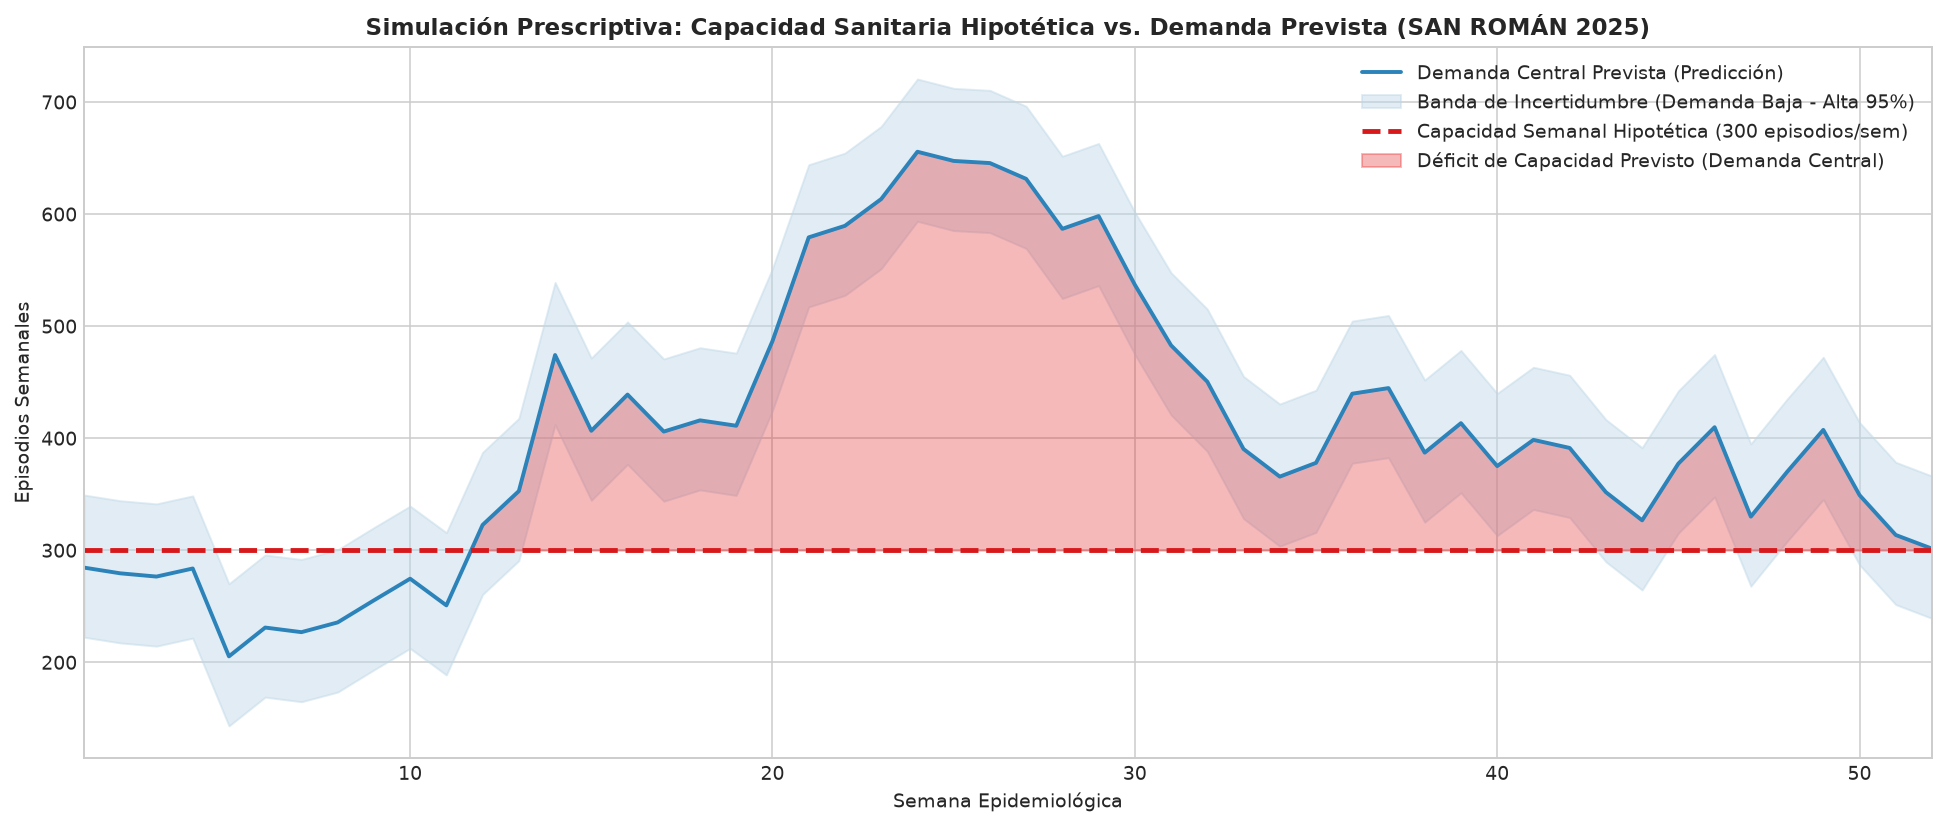

In [11]:
# Visualización Cuantitativa de la Simulación Prescriptiva
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(sim_sr["Semana"], sim_sr["Demanda_Central_Pred"], color="#2b83ba", lw=2, label="Demanda Central Prevista (Predicción)")
ax.fill_between(sim_sr["Semana"], sim_sr["Demanda_Baja_P025"], sim_sr["Demanda_Alta_P975"], color="#bdd7e7", alpha=0.45, label="Banda de Incertidumbre (Demanda Baja - Alta 95%)")
ax.axhline(300.0, color="#d7191c", lw=2.5, linestyle="--", label="Capacidad Semanal Hipotética (300 episodios/sem)")

# Sombrear la zona de déficit bajo escenario central
ax.fill_between(
    sim_sr["Semana"],
    300.0,
    sim_sr["Demanda_Central_Pred"],
    where=(sim_sr["Demanda_Central_Pred"] > 300.0),
    color="#e41a1c",
    alpha=0.3,
    interpolate=True,
    label="Déficit de Capacidad Previsto (Demanda Central)"
)

ax.set_title("Simulación Prescriptiva: Capacidad Sanitaria Hipotética vs. Demanda Prevista (SAN ROMÁN 2025)", fontweight="bold")
ax.set_xlabel("Semana Epidemiológica")
ax.set_ylabel("Episodios Semanales")
ax.set_xlim(1, 52)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [12]:
# Priorización Territorial Departamental según Brecha Máxima de Demanda
# Asumiendo una capacidad hipotética equivalente al promedio histórico de cada provincia
ranking_list = []
test_2025_preds = df_preds[(df_preds["particion"] == "test") & (df_preds["horizonte_h"] == 1) & (df_preds["modelo"] == "XGBoost Global")].copy()

for p_name, grp in test_2025_preds.groupby("entidad"):
    media_hist = df_prov[df_prov["provincia"] == p_name]["ira_no_neumonia"].mean()
    # Supuesto académico: capacidad base igual a la media histórica
    cap_base = round(media_hist, 1)
    
    max_demanda_central = grp["y_pred"].max()
    max_demanda_alta = grp["y_pred_upper_95"].max()
    
    brecha_max_central = max_demanda_central - cap_base
    brecha_max_alta = max_demanda_alta - cap_base
    semanas_deficit = (grp["y_pred"] > cap_base).sum()
    
    ranking_list.append({
        "Provincia": p_name,
        "Capacidad_Base_Hipotetica": cap_base,
        "Pico_Demanda_Central": round(max_demanda_central, 1),
        "Pico_Demanda_Alta_P975": round(max_demanda_alta, 1),
        "Brecha_Pico_Central": round(brecha_max_central, 1),
        "Brecha_Pico_Alta": round(brecha_max_alta, 1),
        "Semanas_Con_Deficit_Previsto": int(semanas_deficit)
    })

df_ranking = pd.DataFrame(ranking_list).sort_values(by="Brecha_Pico_Central", ascending=False).reset_index(drop=True)
df_ranking["Nivel_Prioridad_Logistica"] = ["ALTA" if i < 3 else ("MEDIA" if i < 7 else "ESTABLE") for i in range(len(df_ranking))]

print("--- TABLA 8: PRIORIZACIÓN LOGÍSTICA DEPARTAMENTAL ANTE EL PICO EPIDEMIOLÓGICO 2025 ---")
print(df_ranking[["Provincia", "Nivel_Prioridad_Logistica", "Capacidad_Base_Hipotetica", "Pico_Demanda_Central", "Brecha_Pico_Central", "Semanas_Con_Deficit_Previsto"]].to_string(index=False))

--- TABLA 8: PRIORIZACIÓN LOGÍSTICA DEPARTAMENTAL ANTE EL PICO EPIDEMIOLÓGICO 2025 ---
            Provincia Nivel_Prioridad_Logistica  Capacidad_Base_Hipotetica  Pico_Demanda_Central  Brecha_Pico_Central  Semanas_Con_Deficit_Previsto
            SAN ROMAN                      ALTA                      422.6                 655.6                233.0                            17
                 PUNO                      ALTA                      283.3                 392.0                108.7                            14
                LAMPA                      ALTA                      102.4                 142.4                 40.0                             6
               MELGAR                     MEDIA                      132.9                 163.1                 30.2                             5
             HUANCANE                     MEDIA                       73.6                  96.4                 22.8                            15
            EL COLLAO    

## 6. Conclusiones Generales y Síntesis Académica
1. **Descriptiva:** Se caracterizó fehacientemente la dinámica de 2,297,378 episodios de IRA en 26 años epidemiológicos en Puno, evidenciando una fuerte concentración en San Román y Puno y un ciclo estacional invernal muy regular.
2. **Diagnóstica:** Se demostró la presencia del shock pandémico de 2020 y se auditaron con rigor 153 semanas de ausencia NotiSP conservadas como `NaN`. Se formalizó la separación científica entre observaciones empíricas, asociaciones temporales e hipótesis no demostrables.
3. **Predictiva:** Los modelos ML optimizados (**XGBoost Global** y **LightGBM Global**) superan holgadamente a los baselines, alcanzando WAPEs del **15.91%** en $h=1$ y **18.97%** en $h=4$ directo en la prueba 2025, garantizando particiones sin fugas temporales.
4. **Prescriptiva:** Se desarrolló un simulador cuantitativo de capacidad sanitaria que permite evaluar escenarios de estrés en la demanda (baja, central y alta) para priorizar la asignación temporal y territorial de turnos y recursos logísticos bajo supuestos académicos transparentes.